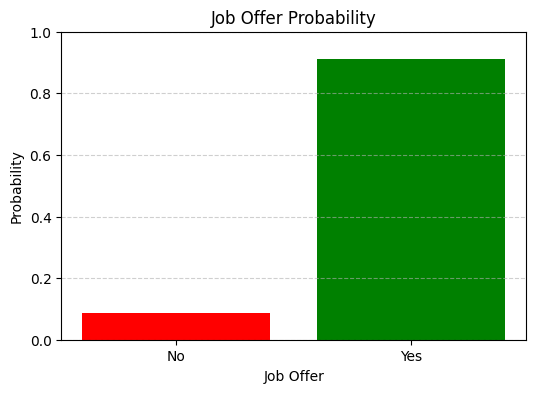

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB
import matplotlib.pyplot as plt

# step1: dataset
data = {
    'CGPA': ['>=9','>=8','>=9','<8','>=8','>=9','<8','>=9','>=8','>=8'],
    'Interactivity': ['Yes','No','No','No','Yes','Yes','Yes','No','Yes','Yes'],
    'practical': ['Very good', 'Good','Average','Average','Good','Good','Good','Very good','Good','Average'],
    'Communication Skills': ['Good','moderate','poor','Good','moderate','moderate','poor','Good','Good','Good'],
    'Job Offer': ['Yes','Yes','No','No','Yes','Yes','No','Yes','Yes','Yes'],
}

df = pd.DataFrame(data)

# step2: encode categorical features

label_encoders = {}
for column in df.columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])
    label_encoders[column] = le

# step 3: split features and target

X = df.drop('Job Offer', axis=1)
y = df['Job Offer']

# step 4: train naive bayes model

model = CategoricalNB()
model.fit(X, y)

# step 5: predict job offer

new_instance = pd.DataFrame([{
    'CGPA': '>=9',
    'Interactivity': 'Yes',
    'practical': 'Good',
    'Communication Skills': 'Good'
}])

# encode the new instance

for column in new_instance.columns:
    new_instance[column] = label_encoders[column].transform(new_instance[column])

# make predictions

proba = model.predict_proba(new_instance)[0]
class_labels = label_encoders['Job Offer'].classes_

# step 7: plot the results

plt.figure(figsize=(6,4))
plt.bar(class_labels, proba, color=['red','green'])
plt.xlabel('Job Offer')
plt.ylabel('Probability')
plt.title('Job Offer Probability')
plt.ylim(0,1)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()